# Anexo A: validaciones de calidad de datos (Planta 2)
Respaldo técnico de las secciones 2 y 3 del cuaderno principal. Cada apartado documenta una validación: qué se probó, con qué datos y qué indica el resultado. Incluye además revisiones que no caben en el cuerpo del cuaderno, como los intervalos entre registros, los rangos físicos, la temperatura del módulo, los saltos bruscos y la prueba de estacionariedad. Se ejecuta de principio a fin con las decisiones adoptadas en el cuaderno principal, que se declaran en la celda de configuración.

## A.1 Preparación de los datos
Las funciones y el dataset son los del cuaderno principal. La tabla final de esta sección muestra cuántas filas quedan en cada paso.

In [1]:
import os, glob, zipfile, warnings, contextlib, io, itertools, json, sys, time, pickle
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, statsmodels, sklearn, xgboost, missingno as msno, joblib
from scipy import stats
from IPython.display import display
from sklearn.base import clone, BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.calibration import CalibratedClassifierCV
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix, cohen_kappa_score,
                             ConfusionMatrixDisplay, classification_report, silhouette_score, mean_squared_error, mean_absolute_error)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from xgboost import XGBClassifier

SEMILLA = 42                                   # no es una decisión analítica: solo reproducibilidad
np.random.seed(SEMILLA)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)    # saga con pocas filas avisa a veces; no cambia las conclusiones
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)
os.makedirs('figuras', exist_ok=True)
print('Versiones -> python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__, '| matplotlib', matplotlib.__version__,
      '| seaborn', sns.__version__, '| scipy', scipy.__version__, '| statsmodels', statsmodels.__version__, '| scikit-learn', sklearn.__version__,
      '| xgboost', xgboost.__version__, '| missingno', msno.__version__, '| joblib', joblib.__version__)

Versiones -> python 3.13.3 | pandas 3.1.1 | numpy 2.5.4 | matplotlib 3.11.2 | seaborn 0.13.2 | scipy 1.18.1 | statsmodels 0.15.0 | scikit-learn 1.9.1 | xgboost 3.4.1 | missingno 0.5.2 | joblib 1.6.0


In [2]:
def buscar_datos(archivo='Plant_2_Weather_Sensor_Data.csv', carpetas=('.', 'Solar_Power', '../../Solar_Power', '../Data', 'datos_solar')):
    """Devuelve la carpeta donde están los CSV del dataset de Kaggle."""
    for carpeta in carpetas:
        hallados = glob.glob(os.path.join(carpeta, '**', archivo), recursive=True)
        if hallados:
            return os.path.dirname(hallados[0])
    for ruta_zip in glob.glob('*.zip'):
        with zipfile.ZipFile(ruta_zip) as z:
            if any(n.endswith(archivo) for n in z.namelist()):
                z.extractall('datos_solar')
                return buscar_datos(archivo, ('datos_solar',))
    raise FileNotFoundError(f'No se encontró {archivo}. Descarguen el ZIP desde Kaggle y déjenlo en la carpeta del notebook.')

def agregar_rezagos(df, columna, pasos=(1, 2, 4), freq='15min'):
    """Rezagos por fecha (no por posición): si falta el registro anterior queda NaN."""
    serie = df.set_index('DATE_TIME')[columna]
    if not serie.index.is_unique:
        raise ValueError('Hay fechas repetidas: agreguen o eliminen duplicados primero.')
    for p in pasos:
        pasado = serie.shift(p, freq=freq)
        df[f'{columna}_lag{p}'] = df['DATE_TIME'].map(pasado)
    return df

def crear_niveles(train, test, columna, n_niveles=3, etiquetas=None, umbrales=None, nombre='nivel'):
    """Variable objetivo por cuantiles de TRAIN, aplicados igual a test."""
    if umbrales is None:
        cortes = [float(train[columna].quantile(i / n_niveles)) for i in range(1, n_niveles)]
    else:
        cortes = sorted(float(u) for u in umbrales); n_niveles = len(cortes) + 1
    if len(set(cortes)) != len(cortes):
        raise ValueError(f'Cortes repetidos {cortes}.')
    if etiquetas is None:
        etiquetas = {2: ['bajo', 'alto'], 3: ['bajo', 'medio', 'alto']}.get(n_niveles, [f'nivel_{i + 1}' for i in range(n_niveles)])
    limites = [-np.inf] + cortes + [np.inf]
    train, test = train.copy(), test.copy()
    for d_ in (train, test):
        d_[nombre] = pd.cut(d_[columna], bins=limites, labels=etiquetas)
    print('Cortes (calculados con train):', [round(c, 1) for c in cortes])
    print('Proporción por clase en train:', train[nombre].value_counts(normalize=True).round(2).to_dict())
    print('Proporción por clase en test: ', test[nombre].value_counts(normalize=True).round(2).to_dict())
    return train, test, cortes

COLS_SENSOR = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']

def construir_malla(gen, sen):
    """Pasa a formato ancho sobre la malla completa de instantes de 15 min (los ausentes quedan vacíos)."""
    ac = gen.pivot(index='DATE_TIME', columns='SOURCE_KEY', values='AC_POWER')
    dc = gen.pivot(index='DATE_TIME', columns='SOURCE_KEY', values='DC_POWER')
    malla = pd.date_range(gen.DATE_TIME.min().normalize(), gen.DATE_TIME.max().normalize() + pd.Timedelta(hours=23, minutes=45),
                          freq='15min', name='DATE_TIME')
    ac, dc = ac.reindex(malla), dc.reindex(malla)
    d = sen.set_index('DATE_TIME')[COLS_SENSOR].reindex(malla)
    d['n_inv'] = ac.notna().sum(axis=1)                 # inversores que reportan
    d['AC_OBS_KW'] = ac.sum(axis=1, min_count=1)        # suma observada
    d['n_inv_cero'] = (ac == 0).sum(axis=1)             # inversores que reportan AC = 0
    return ac, dc, d

def _params_activos(ac_w, cols, idx):
    """Por cada inversor ausente: r (su potencia frente al promedio de los que producen) y p0 (frecuencia de AC = 0 con sol)."""
    pe = ac_w.loc[idx].drop(columns=cols)
    prom_act = pe.where(pe > 0).mean(axis=1)
    r = {c: (ac_w.loc[idx, c].where(ac_w.loc[idx, c] > 0) / prom_act).mean() for c in cols}
    p0 = {c: (ac_w.loc[idx, c] == 0).mean() for c in cols}
    return r, p0

def _ausentes(ac_w, cols, r, p0):
    """Potencia que habrían aportado los inversores `cols` en las filas de ac_w."""
    pres = ac_w.drop(columns=cols)
    prom_act = pres.where(pres > 0).mean(axis=1).fillna(0)
    return sum(r[c] * (1 - p0[c]) * prom_act for c in cols)

def preparar_planta2(gen, sen, umbral, tratar_incompletos, interpolar_ausentes, tratar_planta_en_cero, frac_dias_train, lags):
    """Dataset de modelado de la Planta 2 y un diccionario `ctx` con los objetos intermedios (para la exploración y las pruebas de calidad)."""
    predictores = ['hora'] + [f'AC_PLANTA_KW_lag{p}' for p in lags] + [f'{c}_lag{p}' for c in COLS_SENSOR for p in lags]
    ac, dc, d = construir_malla(gen, sen)
    inv = list(ac.columns); n_tot = len(inv)
    sol = d.IRRADIATION > umbral
    dias = pd.DatetimeIndex(d.index.normalize().unique()).sort_values()
    n_tr = int(frac_dias_train * len(dias))
    dias_tr, dias_te = dias[:n_tr], dias[n_tr:]

    inc = d.index[d.n_inv.between(1, n_tot - 1)]
    falt = ac.loc[inc].isna()
    patron = pd.Series([tuple(c for c in inv if f[c]) for _, f in falt.iterrows()], index=inc, dtype=object)
    d['AC_PLANTA_KW'] = d['AC_OBS_KW']
    params = {}
    if tratar_incompletos == 'corregir':
        base = d.index[(d.n_inv == n_tot) & sol & d.index.normalize().isin(dias_tr)]     # solo días de entrenamiento
        for p in patron.unique():
            cols = list(p)
            params[p] = _params_activos(ac, cols, base)
            idx = patron.index[patron == p]
            d.loc[idx, 'AC_PLANTA_KW'] = d.loc[idx, 'AC_OBS_KW'] + _ausentes(ac.loc[idx], cols, *params[p])
    elif tratar_incompletos == 'excluir':
        d.loc[inc, 'AC_PLANTA_KW'] = np.nan
    elif tratar_incompletos != 'mantener':
        raise ValueError("tratar_incompletos debe ser 'corregir', 'excluir' o 'mantener'")

    d['imputado'] = d.n_inv == 0                              # instantes que no existen en los archivos
    d['n_inv_cero'] = d['n_inv_cero'].where(~d.imputado, 0)
    if interpolar_ausentes:
        ci = COLS_SENSOR + ['AC_PLANTA_KW']
        d.loc[d.imputado, ci] = d[ci].interpolate(method='time', limit=1, limit_area='inside').loc[d.imputado, ci]

    Dp = d.reset_index()
    for col in ['AC_PLANTA_KW'] + COLS_SENSOR:
        Dp = agregar_rezagos(Dp, col, pasos=lags)             # rezagos por fecha, ANTES de filtrar las horas de sol
    Dp = agregar_rezagos(Dp, 'n_inv_cero', pasos=(1,))
    Dp['hora'] = Dp.DATE_TIME.dt.hour + Dp.DATE_TIME.dt.minute / 60
    Dp['fecha'] = Dp.DATE_TIME.dt.normalize()

    x = Dp[~Dp.imputado]
    x = x[x.IRRADIATION > umbral]
    if tratar_planta_en_cero == 'excluir':
        x = x[~((x.n_inv > 0) & (x.n_inv_cero == x.n_inv))]
    elif tratar_planta_en_cero != 'mantener':
        raise ValueError("tratar_planta_en_cero debe ser 'mantener' o 'excluir'")
    ds = x.dropna(subset=['AC_PLANTA_KW'] + predictores)
    ctx = dict(ac=ac, dc=dc, d=d, D=Dp, inv=inv, patron=patron, params=params, umbral=umbral,
               dias=dias, dias_train=dias_tr, dias_test=dias_te)
    return ds, ctx

def validar_correccion(ctx, minimo_kw=1000):
    """Oculta los inversores de cada patrón de ausencia en instantes completos y compara la suma sin corregir y corregida."""
    ac_, d_, inv_ = ctx['ac'], ctx['d'], ctx['inv']
    base = d_.index[(d_.n_inv == len(inv_)) & (d_.IRRADIATION > ctx['umbral']) & d_.index.normalize().isin(ctx['dias_train'])]
    dias_b = pd.DatetimeIndex(base.normalize().unique()).sort_values()
    idx_est, idx_ev = base[base.normalize().isin(dias_b[::2])], base[base.normalize().isin(dias_b[1::2])]
    filas = []
    for p in ctx['patron'].unique():
        cols = list(p)
        r, p0 = _params_activos(ac_, cols, idx_est)
        real = ac_.loc[idx_ev].sum(axis=1)
        pres = ac_.loc[idx_ev].drop(columns=cols).sum(axis=1)
        corr = pres + _ausentes(ac_.loc[idx_ev], cols, r, p0)
        ok = real > minimo_kw
        e0, e1 = ((pres - real) / real)[ok], ((corr - real) / real)[ok]
        filas.append({'inversores ausentes': len(cols), 'sesgo sin corregir %': 100 * e0.mean(),
                      'error abs. sin corregir %': 100 * e0.abs().mean(), 'error abs. corregido %': 100 * e1.abs().mean()})
    return pd.DataFrame(filas).sort_values('inversores ausentes').round(1)

def error_interpolacion(d_, n_inv_total, sol):
    """Error mediano (%) de estimar un instante con el promedio de sus vecinos y % de veces que cambia la clase."""
    vec3 = (d_.n_inv == n_inv_total) & (d_.n_inv.shift(1) == n_inv_total) & (d_.n_inv.shift(-1) == n_inv_total) & sol & ~d_.imputado
    cortes_ = np.quantile(d_.loc[(d_.n_inv == n_inv_total) & sol, 'AC_OBS_KW'], [1 / 3, 2 / 3])
    est = (d_.AC_OBS_KW.shift(1) + d_.AC_OBS_KW.shift(-1)) / 2
    ok = vec3 & (d_.AC_OBS_KW > 1000)
    e = ((est - d_.AC_OBS_KW) / d_.AC_OBS_KW)[ok]
    cambia = (np.digitize(est[vec3], cortes_) != np.digitize(d_.loc[vec3, 'AC_OBS_KW'], cortes_)).mean()
    return 100 * e.abs().median(), 100 * cambia

print('Funciones definidas.')

Funciones definidas.


In [3]:
# Decisiones adoptadas en el cuaderno principal (fases 3 a 5); aquí solo se reutilizan, no se vuelven a discutir
UMBRAL_IRR = 0.02
TRATAR_INCOMPLETOS = 'corregir'
INTERPOLAR_AUSENTES = False
TRATAR_PLANTA_EN_CERO = 'mantener'
FRAC_DIAS_TRAIN = 0.80
LAGS = (1, 2, 4)
HORA_VAR = 'dist_mediodia'
HORA_ELEGIDA = HORA_VAR
RECALL_MIN_BAJO = 0.70
LAGS_POTENCIA = [f'AC_PLANTA_KW_lag{p}' for p in LAGS]
LAGS_SENSOR = [f'{c_}_lag{p}' for c_ in COLS_SENSOR for p in LAGS]
PREDICTORES = ['hora'] + LAGS_POTENCIA + LAGS_SENSOR

In [4]:
ruta = buscar_datos()
FMT = '%Y-%m-%d %H:%M:%S'
# La fecha llega como texto: se convierte con formato explícito y se cuentan las fechas inválidas
for archivo in ['Plant_2_Generation_Data.csv', 'Plant_2_Weather_Sensor_Data.csv']:
    txt = pd.read_csv(os.path.join(ruta, archivo), usecols=['DATE_TIME'], dtype=str)['DATE_TIME']
    invalidas = int(pd.to_datetime(txt, format=FMT, errors='coerce').isna().sum())
    print(f'{archivo}: tipo antes de convertir = {txt.dtype} | fechas inválidas con format={FMT!r}: {invalidas}')
gen = pd.read_csv(os.path.join(ruta, 'Plant_2_Generation_Data.csv'), parse_dates=['DATE_TIME'], date_format=FMT)
sen = pd.read_csv(os.path.join(ruta, 'Plant_2_Weather_Sensor_Data.csv'), parse_dates=['DATE_TIME'], date_format=FMT)
print('Datos en:', ruta)
print('Tipo después de convertir:', gen.DATE_TIME.dtype, '|', sen.DATE_TIME.dtype)

Plant_2_Generation_Data.csv: tipo antes de convertir = str | fechas inválidas con format='%Y-%m-%d %H:%M:%S': 0
Plant_2_Weather_Sensor_Data.csv: tipo antes de convertir = str | fechas inválidas con format='%Y-%m-%d %H:%M:%S': 0
Datos en: ../../Solar_Power\Data
Tipo después de convertir: datetime64[us] | datetime64[us]


In [5]:
def preparar(gen, sen, **cambios):
    """preparar_planta2 con las decisiones de 3.1 y 3.2; `cambios` modifica una o más (sensibilidad, evaluación día a día)."""
    p = dict(umbral=UMBRAL_IRR, tratar_incompletos=TRATAR_INCOMPLETOS, interpolar_ausentes=INTERPOLAR_AUSENTES,
             tratar_planta_en_cero=TRATAR_PLANTA_EN_CERO, frac_dias_train=FRAC_DIAS_TRAIN, lags=LAGS)
    p.update(cambios)
    return preparar_planta2(gen, sen, **p)

ds, ctx = preparar(gen, sen)
D, d, ac, dc = ctx['D'], ctx['d'], ctx['ac'], ctx['dc']
N_INV = len(ctx['inv']); dias_train, dias_test = ctx['dias_train'], ctx['dias_test']
sol_t = d.IRRADIATION > UMBRAL_IRR

pasos = [('Instantes de la malla (34 días por 96)', D),
         ('Sin los instantes ausentes', D[~D.imputado]),
         (f'Solo horas de sol (IRRADIATION > {UMBRAL_IRR})', D[~D.imputado & (D.IRRADIATION > UMBRAL_IRR)]),
         ('Sin vacíos en el objetivo ni en los rezagos (dataset de modelado)', ds)]
embudo = pd.DataFrame({'paso': [p[0] for p in pasos], 'filas': [len(p[1]) for p in pasos]})
embudo['filas quitadas'] = (-embudo.filas.diff()).fillna(0).astype(int)
display(embudo)
print(f'Dataset de modelado: {len(ds)} filas, {ds.fecha.nunique()} días | entrenamiento {int(ds.fecha.isin(dias_train).sum())} filas '
      f'({len(dias_train)} días), prueba {int(ds.fecha.isin(dias_test).sum())} filas ({len(dias_test)} días)')

,paso,filas,filas quitadas
0,Instantes de la malla (34 días por 96),3264,0
1,Sin los instantes ausentes,3259,5
2,Solo horas de sol (IRRADIATION > 0.02),1623,1636
3,Sin vacíos en el objetivo ni en los rezagos (d...,1615,8


Dataset de modelado: 1615 filas, 34 días | entrenamiento 1275 filas (27 días), prueba 340 filas (7 días)


In [6]:
# Objetos que usa el código del anexo (vienen de preparar_planta2)
df = ctx['d'].copy()                              # malla completa de instantes con n_inv, AC_OBS_KW, AC_PLANTA_KW, imputado...
ac_wide, dc_wide = ctx['ac'], ctx['dc']
inversores = ctx['inv']; cols_sensor = COLS_SENSOR
D = ctx['D']
PLANTA_CERO = (D.n_inv > 0) & (D.n_inv_cero == D.n_inv)

## A.2 Intervalos entre registros y faltantes por día
Cada intervalo distinto de 15 minutos es un hueco en la serie. También se cuenta cuántos días tienen instantes ausentes o con inversores faltantes.

In [7]:
# tiempo entre registros consecutivos de cada archivo
def intervalos(serie):
    t = pd.Series(sorted(serie.unique()))
    return t.diff().dropna().value_counts().sort_index().rename('veces')
tab_int = pd.concat({'generación': intervalos(gen.DATE_TIME), 'sensor': intervalos(sen.DATE_TIME)}, axis=1).fillna(0).astype(int)
tab_int.index = [str(i).replace('0 days ', '') for i in tab_int.index]
display(tab_int)
print('Cada intervalo distinto de 00:15:00 es un hueco: 00:30:00 = falta 1 instante; 00:45:00 = faltan 2; y así.')

# faltantes por día (instantes sin ningún inversor, e instantes de sol con inversores ausentes)
dia_idx = d.index.normalize()
por_dia = pd.DataFrame({'instantes ausentes': (d.n_inv == 0).groupby(dia_idx).sum(),
                        'instantes de sol incompletos': (sol_t & d.n_inv.between(1, N_INV - 1)).groupby(dia_idx).sum()})
por_dia = por_dia[(por_dia > 0).any(axis=1)]
por_dia.index = por_dia.index.strftime('%d-%m')
print(f'Días con algún instante ausente o incompleto: {len(por_dia)} de {dia_idx.nunique()}')
display(por_dia.T)

,generación,sensor
00:15:00,3253,3253
00:30:00,5,5


Cada intervalo distinto de 00:15:00 es un hueco: 00:30:00 = falta 1 instante; 00:45:00 = faltan 2; y así.
Días con algún instante ausente o incompleto: 14 de 34


DATE_TIME,15-05,19-05,20-05,21-05,22-05,23-05,24-05,25-05,26-05,27-05,28-05,29-05,01-06,03-06
instantes ausentes,1,1,0,0,0,0,0,0,0,0,0,1,1,1
instantes de sol incompletos,0,0,32,49,48,49,49,46,49,49,49,39,0,0


Los dos archivos tienen exactamente los mismos cinco huecos de un solo instante, así que ninguno de los dos sensores perdió información por separado: cuando falla la adquisición, falla en todo el sistema. Los huecos son cortos y aislados (uno en cada uno de cinco días). Lo realmente importante aparece en la segunda tabla: 14 de los 34 días tienen algo irregular, pero diez de ellos, del 20 al 29 de mayo, tienen casi todas las lecturas con sol incompletas. No son pérdidas puntuales sino un grupo de inversores que dejó de reportar durante más de una semana.

## A.3 Rangos físicos, coherencia entre AC y DC y atípicos por hora
Se comprueba que las variables estén dentro de rangos físicos razonables y se buscan atípicos con el IQR calculado dentro de cada hora del día, confirmados con una regla física (kW por kW/m²).

In [8]:
# rangos físicos y resumen
rangos = [('IRRADIATION', sen, 0, 1.5), ('MODULE_TEMPERATURE', sen, -5, 90), ('AMBIENT_TEMPERATURE', sen, -5, 50),
          ('AC_POWER', gen, 0, np.inf), ('DC_POWER', gen, 0, np.inf)]
filas = []
for v, tabla_, lo, hi in rangos:
    x = tabla_[v]
    filas.append({'variable': v, 'mínimo': x.min(), 'máximo': x.max(), 'rango físico': f'{lo} a {hi}', 'fuera de rango': int(((x < lo) | (x > hi)).sum())})
display(pd.DataFrame(filas).round(2))
print('Registros con AC > DC:', int((gen.AC_POWER > gen.DC_POWER).sum()), '| cociente AC/DC máximo (DC > 0):', round((gen.AC_POWER / gen.DC_POWER.where(gen.DC_POWER > 0)).max(), 3))
print('Resumen en horas de sol:'); print(ds[['AC_PLANTA_KW'] + COLS_SENSOR].describe().round(2).T.to_string())

# atípicos con el IQR calculado dentro de cada hora del día y confirmados con una regla física (kW por kW/m²)
base_hr = d[sol_t & (d.n_inv == N_INV)].copy(); base_hr['h'] = base_hr.index.hour
def marcados(k):
    q1 = base_hr.groupby('h').AC_OBS_KW.transform(lambda s: s.quantile(.25)); q3 = base_hr.groupby('h').AC_OBS_KW.transform(lambda s: s.quantile(.75))
    return (base_hr.AC_OBS_KW > q3 + k * (q3 - q1)) | (base_hr.AC_OBS_KW < q1 - k * (q3 - q1))
print(f'Instantes marcados según k (de {len(base_hr)}):', {k: int(marcados(k).sum()) for k in (1.5, 2, 3)})
for k_ in (1.5, 2, 3):
    m_ = base_hr[marcados(k_)]
    print(f'k = {k_}: {len(m_)} instantes marcados; con inversores en cero: {int((m_.n_inv_cero > 0).sum())}; sin inversores en cero: {int((m_.n_inv_cero == 0).sum())}')
K_IQR = 2     # el grupo decide k: con 3 no se marca nada; con 1.5 aparecen más instantes que hay que revisar uno a uno
atip = base_hr[marcados(K_IQR)].copy()
atip['kW por kW/m²'] = atip.AC_OBS_KW / atip.IRRADIATION
atip['decisión'] = np.where(atip.n_inv_cero > 0, 'se conserva: inversores en cero (evento real)', 'se conserva: sin explicación en los datos')
print(f'Con k = {K_IQR} (referencia: mediana de toda la planta = {(base_hr.AC_OBS_KW / base_hr.IRRADIATION).median():,.0f} kW por kW/m²):')
display(atip[['AC_OBS_KW', 'IRRADIATION', 'kW por kW/m²', 'n_inv_cero', 'decisión']].round(2).head(25))
print(f'{len(atip)} instantes marcados ({100 * len(atip) / len(base_hr):.1f} %); con inversores en cero: {int((atip.n_inv_cero > 0).sum())}; sin explicación: {int((atip.n_inv_cero == 0).sum())}. No se elimina ninguno.')

,variable,mínimo,máximo,rango físico,fuera de rango
0,IRRADIATION,0.00,1.10,0 a 1.5,0
1,MODULE_TEMPERATURE,20.27,66.64,-5 a 90,0
2,AMBIENT_TEMPERATURE,20.94,39.18,-5 a 50,0
3,AC_POWER,0.00,1385.42,0 a inf,0
4,DC_POWER,0.00,1420.93,0 a inf,0


Registros con AC > DC: 18 | cociente AC/DC máximo (DC > 0): 1.008
Resumen en horas de sol:
                      count      mean      std    min      25%       50%       75%       max
AC_PLANTA_KW         1615.0  11003.30  5977.85   0.00  5637.28  11855.38  15821.21  25979.76
AMBIENT_TEMPERATURE  1615.0     30.43     3.89  22.75    27.25     30.26     33.61     39.18
MODULE_TEMPERATURE   1615.0     41.16    10.59  21.64    32.44     40.54     50.27     66.64
IRRADIATION          1615.0      0.47     0.30   0.02     0.20      0.44      0.74      1.10
Instantes marcados según k (de 1164): {1.5: 23, 2: 8, 3: 0}
k = 1.5: 23 instantes marcados; con inversores en cero: 9; sin inversores en cero: 14
k = 2: 8 instantes marcados; con inversores en cero: 5; sin inversores en cero: 3
k = 3: 0 instantes marcados; con inversores en cero: 0; sin inversores en cero: 0
Con k = 2 (referencia: mediana de toda la planta = 30,056 kW por kW/m²):


,AC_OBS_KW,IRRADIATION,kW por kW/m²,n_inv_cero,decisión
DATE_TIME,,,,,
2020-06-01 13:30:00,955.15,0.03,31468.36,0,se conserva: sin explicación en los datos
2020-06-02 06:45:00,5207.33,0.15,35244.29,0,se conserva: sin explicación en los datos
2020-06-02 12:30:00,0.00,1.08,0.00,22,se conserva: inversores en cero (evento real)
2020-06-10 11:15:00,0.00,0.77,0.00,22,se conserva: inversores en cero (evento real)
2020-06-10 11:30:00,0.00,0.78,0.00,22,se conserva: inversores en cero (evento real)
2020-06-11 12:00:00,0.00,0.62,0.00,22,se conserva: inversores en cero (evento real)
2020-06-11 12:15:00,1287.88,0.39,3317.85,0,se conserva: sin explicación en los datos
2020-06-13 10:45:00,0.00,0.50,0.00,22,se conserva: inversores en cero (evento real)


8 instantes marcados (0.7 %); con inversores en cero: 5; sin explicación: 3. No se elimina ninguno.


Las variables están dentro de rangos físicos razonables y no hay valores imposibles. Hay 18 registros en los que la potencia AC supera a la DC, pero el cociente máximo es 1,008: menos de un 1 % por encima, que se explica por redondeos o desfases de medición y no por un problema del inversor. En los atípicos por hora, el resultado depende mucho de qué tan estricta sea la regla: con k = 1,5 se marcan 23 instantes, con k = 2 solo 8 y con k = 3 ninguno. De los 8 de k = 2, cinco son instantes con toda la planta en cero, un fenómeno que ya se estudió aparte, y los otros tres no muestran señal de error de medición: uno ocurre al amanecer, otro al mediodía con casi nada de irradiancia y una potencia proporcional a ella, y el tercero, del 11 de junio, rinde mucho menos de lo que su irradiancia sugiere (unos 3 300 kW por kW/m² frente a una mediana de 30 000), lo que podría ser una pérdida parcial real. Por eso no se elimina ninguno.

## A.4 Temperatura del módulo
Cuánto se calienta el módulo por encima de la temperatura ambiente según la irradiancia.

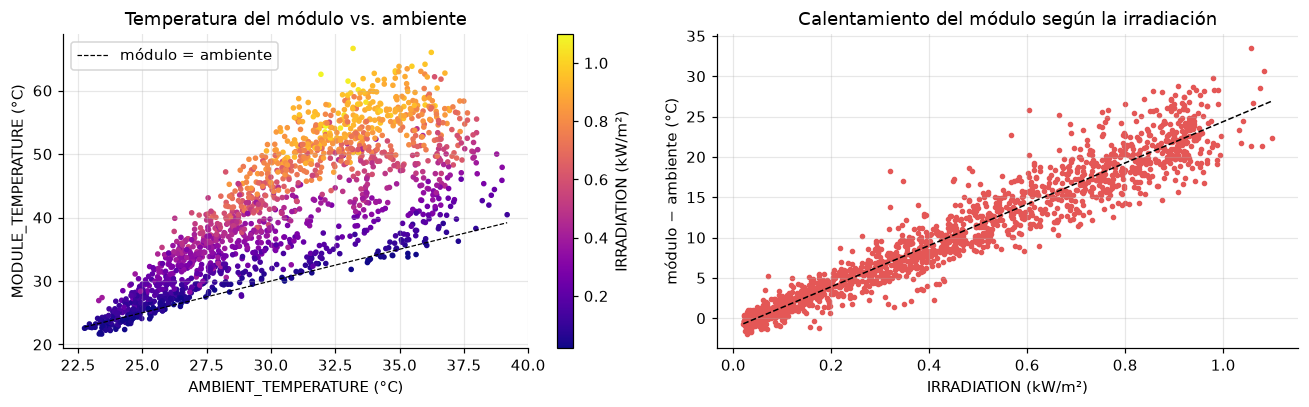

,pendiente (°C por kW/m²),intercepto (°C),correlación,exceso máximo (°C)
módulo menos ambiente,25.58,-1.21,0.96,33.45


In [9]:
ds = ds.assign(exceso_T=ds.MODULE_TEMPERATURE - ds.AMBIENT_TEMPERATURE)
c_ex = np.polyfit(ds.IRRADIATION, ds.exceso_T, 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sc = ax[0].scatter(ds.AMBIENT_TEMPERATURE, ds.MODULE_TEMPERATURE, c=ds.IRRADIATION, s=7, cmap='plasma')
lim = [ds.AMBIENT_TEMPERATURE.min(), ds.AMBIENT_TEMPERATURE.max()]
ax[0].plot(lim, lim, 'k--', lw=.8, label='módulo = ambiente'); ax[0].legend()
ax[0].set_xlabel('AMBIENT_TEMPERATURE (°C)'); ax[0].set_ylabel('MODULE_TEMPERATURE (°C)')
fig.colorbar(sc, ax=ax[0], label='IRRADIATION (kW/m²)'); ax[0].set_title('Temperatura del módulo vs. ambiente')
ax[1].scatter(ds.IRRADIATION, ds.exceso_T, s=7, color='#e45756')
xs = np.linspace(ds.IRRADIATION.min(), ds.IRRADIATION.max(), 20); ax[1].plot(xs, np.polyval(c_ex, xs), 'k--', lw=1)
ax[1].set_xlabel('IRRADIATION (kW/m²)'); ax[1].set_ylabel('módulo − ambiente (°C)'); ax[1].set_title('Calentamiento del módulo según la irradiación')
fig.tight_layout(); fig.savefig('figuras/f4_temperaturas.png', dpi=200, bbox_inches='tight'); plt.show()
display(pd.DataFrame({'pendiente (°C por kW/m²)': [c_ex[0]], 'intercepto (°C)': [c_ex[1]], 'correlación': [ds.exceso_T.corr(ds.IRRADIATION)], 'exceso máximo (°C)': [ds.exceso_T.max()]}, index=['módulo menos ambiente']).round(2))

El módulo se calienta de forma casi proporcional a la irradiancia: la correlación entre el exceso de temperatura y la irradiancia es de 0,96 y la pendiente es de unos 26 °C por cada kW/m², de modo que a pleno sol el módulo supera al ambiente en cerca de 24 °C y en el máximo observado en más de 33 °C. Esto tiene una consecuencia directa para el pronóstico: en las horas de más producción los módulos están más calientes y, por el efecto de la temperatura sobre la eficiencia, rinden menos por cada unidad de irradiancia, lo que ayuda a explicar la curva no lineal de potencia frente a irradiancia del cuaderno principal.

## A.5 Instantes incompletos: qué inversores faltan y por cuánto tiempo
Patrones de ausencia, su duración y cuántos instantes con sol afectan.

Instantes según el número de inversores que reportan:


,instantes
n_inv,
12,64
18,840
22,2355


,patrón,inversores ausentes,instantes,instantes con sol,desde,hasta,inversores
0,P1,4,840,427,2020-05-20 22:00:00,2020-05-29 15:45:00,"IQ2d7, NgDl1, mqwcs, xMbIu"
1,P2,10,64,32,2020-05-19 22:15:00,2020-05-20 14:00:00,"4UPUq, Et9kg, IQ2d7, Mx2yZ, NgDl1, Qf4GU, Quc1..."



Instantes con sol (umbral 0.02): 1623. Incompletos entre ellos: 459 (28.3 %)


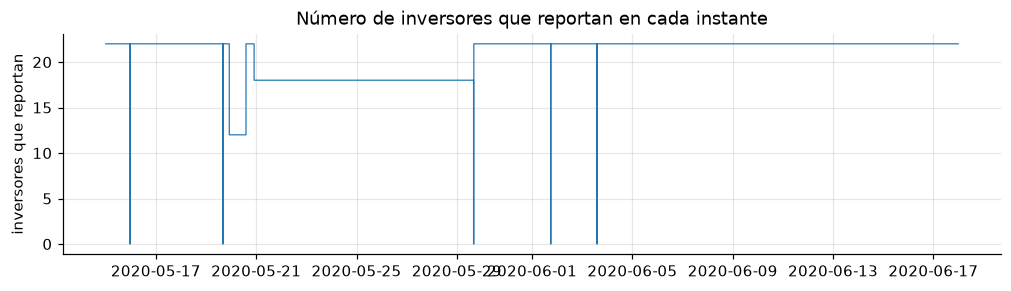

In [10]:
vc = df.loc[df.n_inv > 0, 'n_inv'].value_counts().sort_index()
print('Instantes según el número de inversores que reportan:')
display(vc.rename('instantes').to_frame())

# Qué inversores faltan en cada instante incompleto (patrón de ausencia)
inc_idx = df.index[df.n_inv.between(1, N_INV - 1)]
falt = ac_wide.loc[inc_idx].isna()
patron = pd.Series([tuple(c for c in inversores if f[c]) for _, f in falt.iterrows()], index=inc_idx)
patrones = sorted(patron.unique(), key=lambda p: len(p))
etiqueta = {p: f'P{i + 1}' for i, p in enumerate(patrones)}

sol_t = df.IRRADIATION > UMBRAL_IRR
filas = []
for p in patrones:
    idx = patron.index[patron == p]
    filas.append({'patrón': etiqueta[p], 'inversores ausentes': len(p), 'instantes': len(idx),
                  'instantes con sol': int(sol_t.loc[idx].sum()),
                  'desde': idx.min(), 'hasta': idx.max(),
                  'inversores': ', '.join(c[:5] for c in p)})
display(pd.DataFrame(filas))

n_sol = int(sol_t.sum())
n_sol_inc = int((sol_t & df.n_inv.between(1, N_INV - 1)).sum())
print(f'\nInstantes con sol (umbral {UMBRAL_IRR}): {n_sol}. Incompletos entre ellos: {n_sol_inc} ({100 * n_sol_inc / n_sol:.1f} %)')

fig, ax = plt.subplots(figsize=(11, 2.6))
ax.step(df.index, df.n_inv, where='post', lw=.8)
ax.set_ylabel('inversores que reportan'); ax.set_title('Número de inversores que reportan en cada instante')
fig.savefig('figuras/n_inversores_por_instante.png', dpi=200, bbox_inches='tight'); plt.show()

Solo hay dos patrones de ausencia, y eso simplifica mucho la corrección. El primero, con cuatro inversores faltantes, dura casi diez días (del 20 al 29 de mayo) y afecta a 427 instantes con sol; el segundo, con diez inversores faltantes, dura menos de un día y afecta a 32. En total, el 28 % de las horas con sol tiene algún inversor ausente. Un detalle interesante es que los cuatro inversores del primer patrón aportan en promedio el 22,6 % de la potencia cuando sí reportan, más de lo que les tocaría por su número (4 de 22, es decir, 18,2 %): los inversores que fallan no son "promedio", producen más que el resto. Eso anticipa que escalar la suma por 22 sobre el número de inversores presentes subestimará la potencia.

## A.6 Corrección de instantes incompletos: comparación de métodos
Se oculta cada patrón de ausencia en instantes completos de entrenamiento y se compara la suma sin corregir con tres formas de estimar el aporte de los inversores ausentes.

In [11]:
dias = pd.DatetimeIndex(df.index.normalize().unique()).sort_values()
n_train = int(FRAC_DIAS_TRAIN * len(dias))
dias_train, dias_test = dias[:n_train], dias[n_train:]
es_train = pd.Series(df.index.normalize().isin(dias_train), index=df.index)
print(f'Días: {len(dias)} | entrenamiento: {len(dias_train)} ({dias_train[0].date()} a {dias_train[-1].date()}) '
      f'| prueba: {len(dias_test)} ({dias_test[0].date()} a {dias_test[-1].date()})')

# Instantes completos con sol de los días de entrenamiento
base_tr = df.index[(df.n_inv == N_INV) & sol_t & es_train]

def participacion(cols, idx):
    return ac_wide.loc[idx, cols].sum(axis=1).sum() / ac_wide.loc[idx].sum(axis=1).sum()

share = {p: participacion(list(p), base_tr) for p in patrones}

def parametros_activos(cols, idx):
    """Por cada inversor ausente: factor r (su potencia frente al promedio de los demás inversores que producen)
    y p0 (frecuencia con la que marca cero con sol). Se estiman en los instantes idx."""
    pe = ac_wide.loc[idx].drop(columns=cols)
    prom_act = pe.where(pe > 0).mean(axis=1)
    r = {c: (ac_wide.loc[idx, c].where(ac_wide.loc[idx, c] > 0) / prom_act).mean() for c in cols}
    p0 = {c: (ac_wide.loc[idx, c] == 0).mean() for c in cols}
    return r, p0

def estimar_ausentes(ac_w, cols, r, p0):
    """Potencia que habrían aportado los inversores `cols` en las filas de ac_w."""
    pres = ac_w.drop(columns=cols)
    prom_act = pres.where(pres > 0).mean(axis=1).fillna(0)       # si ninguno produce, no se suma nada
    return sum(r[c] * (1 - p0[c]) * prom_act for c in cols)

params = {p: parametros_activos(list(p), base_tr) for p in patrones}
for p in patrones:
    print(f'Patrón {etiqueta[p]}: {len(p)} inversores ausentes, participación media en la potencia = {share[p]:.3f} '
          f'(si todos aportaran igual sería {len(p) / N_INV:.3f})')

# Validación de la corrección: se estiman los parámetros en la mitad de los días y se evalúa en la otra mitad
dias_b = pd.DatetimeIndex(base_tr.normalize().unique()).sort_values()
idx_est = base_tr[base_tr.normalize().isin(dias_b[::2])]
idx_ev = base_tr[base_tr.normalize().isin(dias_b[1::2])]
cortes_val = np.quantile(ac_wide.loc[base_tr].sum(axis=1), [1 / 3, 2 / 3])      # terciles de la suma real en entrenamiento
filas = []
for p in patrones:
    cols = list(p)
    s_est = participacion(cols, idx_est)
    r_est, p0_est = parametros_activos(cols, idx_est)
    real = ac_wide.loc[idx_ev].sum(axis=1)
    pres = ac_wide.loc[idx_ev].drop(columns=cols).sum(axis=1)
    ok = real > 1000
    metodos = [('sin corregir', pres),
               ('escalar 22/n', pres * N_INV / (N_INV - len(cols))),
               ('dividir entre 1 - s', pres / (1 - s_est)),
               ('inversores activos (propuesto)', pres + estimar_ausentes(ac_wide.loc[idx_ev], cols, r_est, p0_est))]
    for nombre, estim in metodos:
        e = ((estim - real) / real)[ok]
        filas.append({'patrón': etiqueta[p], 'inversores ausentes': len(p), 'método': nombre,
                      'sesgo medio %': round(100 * e.mean(), 1), 'error abs. medio %': round(100 * e.abs().mean(), 1),
                      'error abs. mediano %': round(100 * e.abs().median(), 1),
                      'error abs. p90 %': round(100 * e.abs().quantile(.9), 1),
                      'cambia de clase %': round(100 * (np.digitize(estim, cortes_val) != np.digitize(real, cortes_val)).mean(), 1)})
print('\nError relativo de la estimación frente a la suma real (instantes completos con potencia > 1000 kW):')
display(pd.DataFrame(filas))

Días: 34 | entrenamiento: 27 (2020-05-15 a 2020-06-10) | prueba: 7 (2020-06-11 a 2020-06-17)
Patrón P1: 4 inversores ausentes, participación media en la potencia = 0.226 (si todos aportaran igual sería 0.182)
Patrón P2: 10 inversores ausentes, participación media en la potencia = 0.501 (si todos aportaran igual sería 0.455)

Error relativo de la estimación frente a la suma real (instantes completos con potencia > 1000 kW):


,patrón,inversores ausentes,método,sesgo medio %,error abs. medio %,error abs. mediano %,error abs. p90 %,cambia de clase %
0,P1,4,sin corregir,-21.9,21.9,19.0,30.6,33.3
1,P1,4,escalar 22/n,-4.6,4.8,1.1,15.2,7.2
2,P1,4,dividir entre 1 - s,0.6,5.8,5.0,10.7,7.2
3,P1,4,inversores activos (propuesto),-0.8,1.4,0.7,4.0,2.1
4,P2,10,sin corregir,-50.4,50.4,46.0,64.1,64.6
5,P2,10,escalar 22/n,-9.1,9.8,1.8,34.2,16.7
6,P2,10,dividir entre 1 - s,-3.5,11.3,6.7,30.1,16.4
7,P2,10,inversores activos (propuesto),-2.6,5.1,3.7,10.0,7.4


La comparación confirma esa sospecha y muestra por qué se eligió el método de los inversores activos. Sin corregir, la suma queda 22 % por debajo de la real con cuatro inversores ausentes y 50 % por debajo con diez, y la clase cambia en uno de cada tres instantes en el primer caso y en dos de cada tres en el segundo. Escalar por 22 sobre n funciona en la mediana (error de 1,1 % y 1,8 %) pero tiene colas pesadas (error p90 de 15 % y 34 %), justo porque los inversores ausentes no son típicos. Dividir entre uno menos la participación estimada no mejora. El método propuesto, que estima el aporte de cada inversor ausente a partir de los que sí reportan y de su frecuencia de ceros, deja el error medio en 1,4 % y 5,1 % y reduce los cambios de clase a 2 % y 7 %, y es el que mejor controla las colas.

## A.7 Partición cronológica frente a aleatoria
La misma métrica con tres formas de partir los datos, para medir cuánto infla el resultado partir filas al azar.

In [12]:
# Demostración: misma métrica con partición cronológica y con partición al azar (árbol de decisión sencillo, solo para esta comparación)
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

def exactitud(tr, te):
    c = [float(tr.AC_PLANTA_KW.quantile(q)) for q in (1 / 3, 2 / 3)]
    y_tr = np.digitize(tr.AC_PLANTA_KW, c); y_te = np.digitize(te.AC_PLANTA_KW, c)
    m = DecisionTreeClassifier(max_depth=6, random_state=SEMILLA).fit(tr[PREDICTORES], y_tr)
    return accuracy_score(y_te, m.predict(te[PREDICTORES]))

acc_crono = exactitud(ds[ds.fecha.isin(dias_train)], ds[ds.fecha.isin(dias_test)])
acc_azar = [exactitud(*train_test_split(ds, test_size=1 - FRAC_DIAS_TRAIN, random_state=sem)) for sem in range(20)]
dias_ds = ds.fecha.unique()
rng = np.random.default_rng(SEMILLA)
acc_dias = []
for _ in range(20):
    d_te = rng.choice(dias_ds, len(dias_test), replace=False)
    acc_dias.append(exactitud(ds[~ds.fecha.isin(d_te)], ds[ds.fecha.isin(d_te)]))
print(f'Exactitud con partición cronológica por días: {acc_crono:.3f}')
print(f'Exactitud con días de prueba elegidos al azar (20 sorteos): media {np.mean(acc_dias):.3f}, mínimo {np.min(acc_dias):.3f}, máximo {np.max(acc_dias):.3f}')
print(f'Exactitud con partición al azar de filas (20 semillas): media {np.mean(acc_azar):.3f}, mínimo {np.min(acc_azar):.3f}, máximo {np.max(acc_azar):.3f}')

Exactitud con partición cronológica por días: 0.756
Exactitud con días de prueba elegidos al azar (20 sorteos): media 0.777, mínimo 0.714, máximo 0.855
Exactitud con partición al azar de filas (20 semillas): media 0.779, mínimo 0.746, máximo 0.811


Partir al azar da una exactitud algo mayor que la partición cronológica (0,78 frente a 0,76), una inflación de unos dos puntos con este árbol y estos datos ya corregidos. Lo más llamativo, sin embargo, es la dispersión: al elegir al azar siete días de prueba la exactitud va de 0,71 a 0,86 según los días que toquen, un rango mucho más ancho que la diferencia entre métodos de partición. Eso muestra que una sola partición de siete días es un instrumento ruidoso, y es la razón principal por la que el cuaderno principal complementa la prueba con una evaluación día a día con intervalos por días completos.

## A.8 Instantes ausentes: prueba de la interpolación
Se oculta un instante con sol y se estima con el promedio de sus vecinos.

In [13]:
# Prueba de la interpolación de un paso: se oculta un instante con sol (con sus dos vecinos completos) y se estima con el promedio de los vecinos
vec3 = (df.n_inv == N_INV) & (df.n_inv.shift(1) == N_INV) & (df.n_inv.shift(-1) == N_INV) & sol_t & ~df.imputado
cortes_int = np.quantile(df.loc[(df.n_inv == N_INV) & sol_t, 'AC_OBS_KW'], [1 / 3, 2 / 3])
filas = []
for nombre, col, minimo in [('potencia AC (kW)', 'AC_OBS_KW', 1000), ('irradiación (kW/m²)', 'IRRADIATION', 0.1)]:
    est_i = (df[col].shift(1) + df[col].shift(-1)) / 2
    ok = vec3 & (df[col] > minimo)
    e = ((est_i - df[col]) / df[col])[ok]
    fila = {'variable': nombre, 'instantes probados': int(ok.sum()), 'error abs. mediano %': round(100 * e.abs().median(), 1),
            'error abs. p90 %': round(100 * e.abs().quantile(.9), 1)}
    if col == 'AC_OBS_KW':
        v = vec3
        fila['cambia de clase %'] = round(100 * (np.digitize(est_i[v], cortes_int) != np.digitize(df.loc[v, col], cortes_int)).mean(), 1)
    filas.append(fila)
print('Error de estimar un instante con el promedio de sus vecinos (instantes con sol y vecinos completos):')
display(pd.DataFrame(filas))

Error de estimar un instante con el promedio de sus vecinos (instantes con sol y vecinos completos):


,variable,instantes probados,error abs. mediano %,error abs. p90 %,cambia de clase %
0,potencia AC (kW),1116,9.6,39.2,18.9
1,irradiación (kW/m²),980,10.1,36.0,NaN


Estimar un instante con el promedio de sus vecinos tiene un error mediano cercano al 10 % tanto en la potencia como en la irradiancia, con un percentil 90 de casi 40 %, y cambia la clase en 19 % de los casos. La razón es física: los instantes que más importan son justamente los de cambio rápido, cuando pasa una nube, y ahí el promedio de los vecinos es peor estimador. Por eso se decidió no interpolar: es preferible perder un instante aislado que inventar uno con una probabilidad alta de caer en la clase equivocada.

## A.9 Lecturas congeladas
Longitud de las corridas de valores idénticos en pasos consecutivos.

In [14]:
def corridas_iguales(serie):
    # Longitud de cada corrida de valores idénticos en pasos consecutivos de 15 minutos
    x = serie[~df.imputado & sol_t]
    seguido = x.index.to_series().diff() == pd.Timedelta('15min')
    grupo = (x.ne(x.shift()) | ~seguido).cumsum()
    return x.groupby(grupo).size()

filas = []
for v in ['IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE', 'AC_OBS_KW']:
    L = corridas_iguales(df[v])
    filas.append({'variable': v, 'corrida más larga (pasos)': int(L.max()), 'corridas de 2 o más': int((L >= 2).sum()),
                  'corridas de 4 o más (1 h)': int((L >= 4).sum())})
display(pd.DataFrame(filas))

x = df.AC_OBS_KW[~df.imputado & sol_t]
rep = (x == x.shift()) | (x == x.shift(-1))
print('Valores repetidos de la potencia en horas de sol:', sorted({round(v, 1) for v in x[rep]}))

,variable,corrida más larga (pasos),corridas de 2 o más,corridas de 4 o más (1 h)
0,IRRADIATION,1,0,0
1,MODULE_TEMPERATURE,1,0,0
2,AMBIENT_TEMPERATURE,1,0,0
3,AC_OBS_KW,2,2,0


Valores repetidos de la potencia en horas de sol: [0.0]


No hay lecturas congeladas en el sensor: ninguna de las tres variables repite un valor en pasos consecutivos. En la potencia hay dos corridas de dos pasos, y los únicos valores repetidos son ceros, que corresponden a los episodios de planta completa en cero y no a un instrumento atascado. Un sensor congelado habría sido un problema grave porque produciría rezagos idénticos que el modelo leería como estabilidad.

## A.10 Saltos bruscos y su corroboración
Se revisa si los mayores saltos de potencia se explican por cambios de irradiancia o por inversores que entran y salen.

In [15]:
consec = (df.index.to_series().diff() == pd.Timedelta('15min'))
ok = consec & (df.n_inv == N_INV) & (df.n_inv.shift() == N_INV) & sol_t & sol_t.shift(fill_value=False)
dI, dA, dZ = df.IRRADIATION.diff()[ok], df.AC_OBS_KW.diff()[ok], df.n_inv_cero.diff()[ok]
print(f'Pasos comparables: {len(dI)}')
print('Cambio de irradiación en 15 min (percentiles 1, 50 y 99 y máximo absoluto):',
      dI.quantile([.01, .5, .99]).round(3).tolist(), round(dI.abs().max(), 3), 'kW/m²')
print(f'Correlación entre el cambio de irradiación y el de potencia: {dI.corr(dA):.2f} (todos los pasos), '
      f'{dI[dZ == 0].corr(dA[dZ == 0]):.2f} (pasos sin cambio en el número de inversores en cero, n = {int((dZ == 0).sum())})')

top_i = dI.abs().nlargest(20).index
print(f'\nLos 20 mayores saltos de irradiación: la potencia se movió en la misma dirección en {int((np.sign(dI[top_i]) == np.sign(dA[top_i])).sum())} de 20')

top_a = dA.abs().nlargest(20).index
causa = pd.Series('sin explicación', index=top_a)
causa[(dI[top_a].abs() > 0.1) & (np.sign(dI[top_a]) != np.sign(dA[top_a]))] = 'irradiación en dirección contraria'
causa[(dI[top_a].abs() > 0.1) & (np.sign(dI[top_a]) == np.sign(dA[top_a]))] = 'cambio de irradiación en la misma dirección'
causa[dZ[top_a].abs() >= 2] = 'cambio de 2 o más inversores en cero'
print('Los 20 mayores saltos de potencia, según lo que los acompaña:')
display(causa.value_counts().to_frame('saltos'))
display(pd.DataFrame({'cambio irradiación': dI[top_a], 'cambio potencia (kW)': dA[top_a], 'cambio inversores en cero': dZ[top_a],
                      'causa': causa})[causa.isin(['sin explicación', 'irradiación en dirección contraria'])].round(2))

Pasos comparables: 1136
Cambio de irradiación en 15 min (percentiles 1, 50 y 99 y máximo absoluto): [-0.373, -0.0, 0.347] 0.694 kW/m²
Correlación entre el cambio de irradiación y el de potencia: 0.62 (todos los pasos), 0.71 (pasos sin cambio en el número de inversores en cero, n = 909)

Los 20 mayores saltos de irradiación: la potencia se movió en la misma dirección en 15 de 20
Los 20 mayores saltos de potencia, según lo que los acompaña:


,saltos
cambio de 2 o más inversores en cero,10
cambio de irradiación en la misma dirección,4
sin explicación,3
irradiación en dirección contraria,3


,cambio irradiación,cambio potencia (kW),cambio inversores en cero,causa
DATE_TIME,,,,
2020-05-19 10:30:00,0.01,13045.78,0.0,sin explicación
2020-06-17 13:45:00,0.15,-12631.11,0.0,irradiación en dirección contraria
2020-06-01 12:15:00,-0.33,11065.85,0.0,irradiación en dirección contraria
2020-06-07 15:45:00,-0.13,10068.03,0.0,irradiación en dirección contraria
2020-06-16 14:15:00,0.04,-9843.58,0.0,sin explicación
2020-06-12 13:15:00,-0.05,9839.78,0.0,sin explicación


Los saltos bruscos de potencia tienen explicación en su mayoría. La correlación entre el cambio de irradiancia y el cambio de potencia es de 0,62, y sube a 0,71 si se excluyen los pasos en que cambia el número de inversores en cero: parte de la dispersión viene de inversores que entran y salen. De los 20 mayores saltos de potencia, diez coinciden con cambios de dos o más inversores en cero, cuatro con un cambio de irradiancia en la misma dirección y tres con irradiancia en dirección contraria, y solo tres quedan sin explicación. Es una buena noticia para la calidad de los datos, y a la vez una confirmación de que los inversores en cero son una fuente real de variabilidad que un pronóstico basado solo en el clima no puede ver.

## A.11 IQR por franja horaria
Atípicos de la potencia con el IQR calculado dentro de cada franja del día.

In [16]:
base_seg = df[sol_t & (df.n_inv == N_INV)].copy()
hora_seg = base_seg.index.hour + base_seg.index.minute / 60
base_seg['franja'] = pd.cut(hora_seg, [5, 9, 12, 15, 20], right=False, labels=['5-9 h', '9-12 h', '12-15 h', '15-20 h'])

def atipicos_iqr(x):
    q1, q3 = x.quantile([.25, .75]); i = q3 - q1
    return pd.Series({'instantes': len(x), 'límite inferior': round(q1 - 1.5 * i), 'límite superior': round(q3 + 1.5 * i),
                      'fuera por abajo': int((x < q1 - 1.5 * i).sum()), 'fuera por arriba': int((x > q3 + 1.5 * i).sum())})

glob = atipicos_iqr(base_seg.AC_OBS_KW)
seg = pd.DataFrame({f: atipicos_iqr(g.AC_OBS_KW) for f, g in base_seg.groupby('franja', observed=True)}).T
print('IQR global de la potencia observada: fuera por abajo', glob['fuera por abajo'], '| fuera por arriba', glob['fuera por arriba'])
display(seg)
print('Total de atípicos segmentando por franja:', int(seg[['fuera por abajo', 'fuera por arriba']].sum().sum()))

IQR global de la potencia observada: fuera por abajo 0 | fuera por arriba 0


,instantes,límite inferior,límite superior,fuera por abajo,fuera por arriba
5-9 h,249,-8051,20222,0,0
9-12 h,288,3000,24113,3,1
12-15 h,290,2877,24514,14,3
15-20 h,337,-9481,23131,0,0


Total de atípicos segmentando por franja: 21


La regla del IQR por franja marca 21 instantes, todos entre las 9 y las 15 h, mientras que el IQR global no marca ninguno: la potencia es tan distinta entre el amanecer y el mediodía que un solo límite global es demasiado holgado, y por eso conviene segmentar. Son pocos instantes (menos del 2 % de los completos) y están concentrados en las horas donde ocurren los episodios de inversores en cero, de modo que se interpretan como eventos operativos y no como errores de medición.

## A.12 Estacionariedad de la potencia (prueba ADF)
La prueba de Dickey-Fuller aumentada se usa junto con la ACF para decidir los rezagos [1]. La hipótesis nula es que la serie no es estacionaria; se aplica a la potencia de la planta en todos los instantes, sin los ausentes.

In [17]:
from statsmodels.tsa.stattools import adfuller
serie_adf = ctx['d'].AC_PLANTA_KW.dropna()
est_adf, p_adf, lags_adf, n_adf, crit_adf, _ = adfuller(serie_adf, autolag='AIC')
print(f'ADF sobre {n_adf} instantes: estadístico = {est_adf:.3f} | valor p = {p_adf:.4f} | rezagos usados = {lags_adf}')
print('Valores críticos:', {k: round(v, 3) for k, v in crit_adf.items()})

ADF sobre 3229 instantes: estadístico = -14.165 | valor p = 0.0000 | rezagos usados = 29
Valores críticos: {'1%': np.float64(-3.432), '5%': np.float64(-2.862), '10%': np.float64(-2.567)}


La prueba rechaza la no estacionariedad con holgura (estadístico de -14,2 frente a un valor crítico de -2,9 al 5 %). Hay que leerlo con cuidado: la serie tiene un ciclo diario muy marcado y la prueba no dice que no haya estacionalidad, sino que no hay una tendencia o raíz unitaria que la haga derivar con el tiempo. La conclusión práctica es que la serie se puede modelar con rezagos y con la hora del día sin necesidad de diferenciarla.

## A.13 Sensibilidad del umbral de irradiancia
Filas y cortes de las clases que resultan con cada umbral de horas de sol.

In [18]:
filas = []
for u in [0.005, 0.01, 0.02, 0.05, 0.10, 0.20]:
    x = D[(~D.imputado) & (D.IRRADIATION > u)].dropna(subset=['AC_PLANTA_KW'] + PREDICTORES)
    if TRATAR_PLANTA_EN_CERO == 'excluir':
        x = x[~PLANTA_CERO.loc[x.index]]
    tr = x[x.fecha.isin(dias_train)]
    q1, q2 = tr.AC_PLANTA_KW.quantile([1 / 3, 2 / 3])
    filas.append({'umbral (kW/m²)': u, 'filas totales': len(x), 'filas entrenamiento': len(tr),
                  'filas prueba': len(x) - len(tr), 'corte bajo-medio (kW)': round(q1), 'corte medio-alto (kW)': round(q2)})
display(pd.DataFrame(filas))

,umbral (kW/m²),filas totales,filas entrenamiento,filas prueba,corte bajo-medio (kW),corte medio-alto (kW)
0,0.005,1695,1341,354,8091,15346
1,0.010,1667,1318,349,8460,15394
2,0.020,1615,1275,340,9043,15466
3,0.050,1519,1202,317,10210,15679
4,0.100,1386,1103,283,11248,15995
5,0.200,1208,986,222,12853,16410


El umbral de irradiancia mueve poco los cortes de la clase alta (el corte entre medio y alto va de unos 15 300 a unos 16 400 kW) pero mucho el corte entre bajo y medio, que sube de unos 8 100 a más de 12 800 kW a medida que se descartan instantes de poca potencia. Es lógico: los terciles se calculan sobre lo que queda, y al quitar el amanecer y el atardecer la clase bajo se "encarece". Con 0,02 quedan 1 615 filas; con 0,01 y 0,05 quedan 1 667 y 1 519, una variación pequeña en tamaño pero con un corte bajo-medio que cambia entre 8 500 y 10 200 kW. Por eso en la sección 5.3 del cuaderno principal se mide cuánto cambia el resultado con esos umbrales alternativos.

## Referencias

[1] S. Cantillo-Luna, R. Moreno-Chuquen, D. Celeita y G. Anders, "Deep and machine learning models to forecast photovoltaic power generation," Energies, vol. 16, art. 4097, 2023, doi: 10.3390/en16104097.